# Early Learning Support: Data Exploration

[Open in Colab](https://colab.research.google.com/github/Junghwan0516/early-learning-support/blob/main/01_data_exploration.ipynb)

## Why this project

My work in education motivates an interest in how learning records can support timely, practical outreach. This project examines whether early online engagement can help an educator prioritize a limited number of learners for review.

**Decision question:** If an educator can review only 10% of learners at day 28, which approach identifies the most learners who later withdraw?

The 10% review capacity and day-28 cutoff are project assumptions, not measured requirements from an institution. This notebook examines associations before predictive modeling.

## Data and prediction boundary

OULAD contains historical records from the UK Open University. This analysis uses the anonymized BBB module and explores only its 2013B training cohort.

- Unit: one learner in one course presentation.
- Observation window: days 0–27 relative to the course start.
- Eligible cohort: registered by day 0 and not withdrawn before day 28.
- Target 1: Withdrawn with a known withdrawal date on or after day 28.
- Target 0: Fail, Pass, or Distinction. Non-withdrawal does not imply academic success.
- Input features exclude learner IDs, final outcomes, withdrawal dates, and later activity.
- Records with missing withdrawal dates or inconsistent outcome/withdrawal information were excluded during preparation.

The CSV contains 5,062 records across three presentations **before** repeated learners are removed from later modeling splits. This is not a count of 5,062 unique people. The present exploratory cohort contains 1,522 records.

Source: Kuzilek, Hlosta & Zdrahal (2015), https://doi.org/10.24432/C5KK69. Derived subset, CC BY 4.0. See `data/README.md` for attribution and transformations.

## 1. Load the derived data

Run cells from top to bottom. Locally, run from the repository root after installing `requirements.txt`. In Colab, the bootstrap cell downloads the helper modules and checksum-verified prepared CSV from this repository when missing. A GPU is not needed.

The input file is a prepared feature table. `00_data_preparation.ipynb` reconstructs it from the official archive and checks value-level agreement.

In [1]:
from pathlib import Path
import urllib.request
import sys

repository_root = 'https://raw.githubusercontent.com/Junghwan0516/early-learning-support/main/'
for filename in ['els.py', 'prepare_data.py']:
    if not Path(filename).exists():
        with urllib.request.urlopen(repository_root + filename, timeout=60) as response:
            Path(filename).write_bytes(response.read())
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import els
els.style()

els.load_data()
data_path = Path('data/features_day28.csv')

In [2]:
df = pd.read_csv(data_path)

print(f"Total records: {df.shape[0]:,}")
print(f"Total columns: {df.shape[1]}")

display(df.head())

Total records: 5,062
Total columns: 12


,code_module,code_presentation,id_student,clicks_w1,clicks_w2,clicks_w3,clicks_w4,active_days,days_since_activity,last_week_change,total_clicks,target
0,BBB,2013B,23629,23.0,5.0,9.0,2.0,5.0,6.0,-7.0,39.0,0
1,BBB,2013B,25107,10.0,0.0,66.0,3.0,5.0,5.0,-63.0,79.0,0
2,BBB,2013B,27891,124.0,18.0,16.0,13.0,7.0,4.0,-3.0,171.0,1
3,BBB,2013B,29144,126.0,0.0,74.0,0.0,9.0,7.0,-74.0,200.0,0
4,BBB,2013B,31663,302.0,97.0,188.0,238.0,27.0,0.0,50.0,825.0,0


## 2. Define the training cohort and check quality

| Feature | Interpretation |
|---|---|
| `clicks_w1`–`clicks_w4` | Weekly recorded clicks during days 0–27 |
| `total_clicks` | Total clicks in the observation window |
| `active_days` | Days with positive recorded activity |
| `days_since_activity` | Day 27 minus the last active day; 28 indicates no observed activity |
| `last_week_change` | Week-4 clicks minus week-3 clicks |

Clicks represent recorded interactions, not study duration or understanding. The zero-activity group is retained.

In [3]:
train = df.loc[
    df["code_module"].eq("BBB")
    & df["code_presentation"].eq("2013B")
].copy()

feature_columns = [
    "clicks_w1",
    "clicks_w2",
    "clicks_w3",
    "clicks_w4",
    "active_days",
    "days_since_activity",
    "last_week_change",
    "total_clicks",
]

print(f"Training records: {len(train):,}")
print(f"Later withdrawals: {int(train['target'].sum()):,}")
print(f"Withdrawal rate: {train['target'].mean():.2%}")

quality_summary = pd.DataFrame({
    "data_type": train[feature_columns + ["target"]].dtypes,
    "missing_values": train[feature_columns + ["target"]].isna().sum(),
})

display(quality_summary)

duplicate_count = train.duplicated(
    ["code_module", "code_presentation", "id_student"]
).sum()

print(f"Duplicate learner-presentation records: {duplicate_count}")

Training records: 1,522
Later withdrawals: 269
Withdrawal rate: 17.67%
Duplicate learner-presentation records: 0


,data_type,missing_values
clicks_w1,float64,0
clicks_w2,float64,0
clicks_w3,float64,0
clicks_w4,float64,0
active_days,float64,0
days_since_activity,float64,0
last_week_change,float64,0
total_clicks,float64,0
target,int64,0


In [4]:
assert not train.empty, 'Training cohort is empty.'
assert duplicate_count == 0, 'Duplicate learner-presentation records found.'
assert not train[feature_columns + ['target']].isna().any().any(), 'Missing values found.'
assert np.isfinite(train[feature_columns].to_numpy()).all(), 'Non-finite feature values found.'
assert train.target.isin([0, 1]).all(), 'Unexpected target values.'
assert train.active_days.between(0, 28).all(), 'Active-day values out of range.'
assert train.days_since_activity.between(0, 28).all(), 'Recency values out of range.'
weekly_columns = ['clicks_w1', 'clicks_w2', 'clicks_w3', 'clicks_w4']
assert train[weekly_columns].ge(0).all().all(), 'Negative weekly clicks found.'
assert np.allclose(train[weekly_columns].sum(axis=1), train.total_clicks)
assert np.allclose(train.clicks_w4 - train.clicks_w3, train.last_week_change)
print('Training data consistency checks passed.')

output_dir = Path('figures')
output_dir.mkdir(exist_ok=True)
report_dir = Path('reports')
report_dir.mkdir(exist_ok=True)
baseline_rate = train.target.mean()
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})

Training data consistency checks passed.


## 3. Outcome imbalance

Before comparing predictive methods, establish how common withdrawal is and why a majority-class prediction is insufficient for outreach.

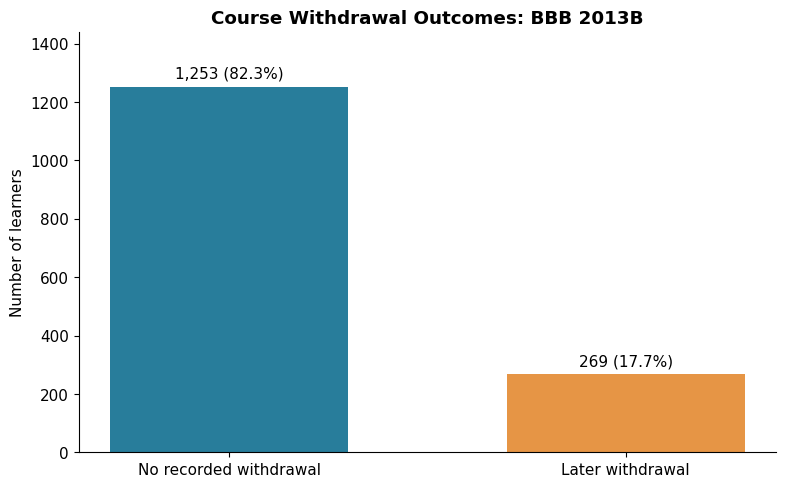

In [5]:
outcome_counts = (
    train["target"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

outcome_labels = [
    "No recorded withdrawal",
    "Later withdrawal",
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    outcome_labels,
    outcome_counts.values,
    color=["#287D9B", "#E69545"],
    width=0.6,
)

for bar, count in zip(bars, outcome_counts.values):
    percentage = count / len(train) * 100

    ax.annotate(
        f"{count:,} ({percentage:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
    )

ax.set_title("Course Withdrawal Outcomes: BBB 2013B")
ax.set_ylabel("Number of learners")
ax.set_ylim(0, outcome_counts.max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.savefig(output_dir / "00_outcome_distribution.png", dpi=200, bbox_inches="tight")
fig.savefig(output_dir / "00_outcome_distribution.svg", bbox_inches="tight")
plt.show()

In [6]:
majority_class_accuracy = train["target"].eq(0).mean()

print(
    "Accuracy when predicting no withdrawal for every learner: "
    f"{majority_class_accuracy:.2%}"
)
print("Withdrawal recall for this approach: 0.00%")

Accuracy when predicting no withdrawal for every learner: 82.33%
Withdrawal recall for this approach: 0.00%


### Interpretation

There are 269 later withdrawals among 1,522 training records (17.67%). Predicting non-withdrawal for everyone achieves 82.33% accuracy while identifying none of the later withdrawals.

For the later modeling stage, the primary selection metric is **Recall@10%**: the fraction of all later withdrawals captured within the highest-ranked 10% of learners. Precision@10%, average precision, lift, and execution time will provide additional context. No model performance is reported in this notebook.

## 4. Withdrawal across activity levels

**Question:** Is later withdrawal less common at higher total activity levels?

Learners are divided into five quantile groups. Ties can produce unequal group sizes. Error bars are pointwise 95% Wilson intervals, under a binomial approximation, for each group's observed withdrawal proportion. They are not simultaneous bands, individual risk intervals, or formal tests of differences between groups.

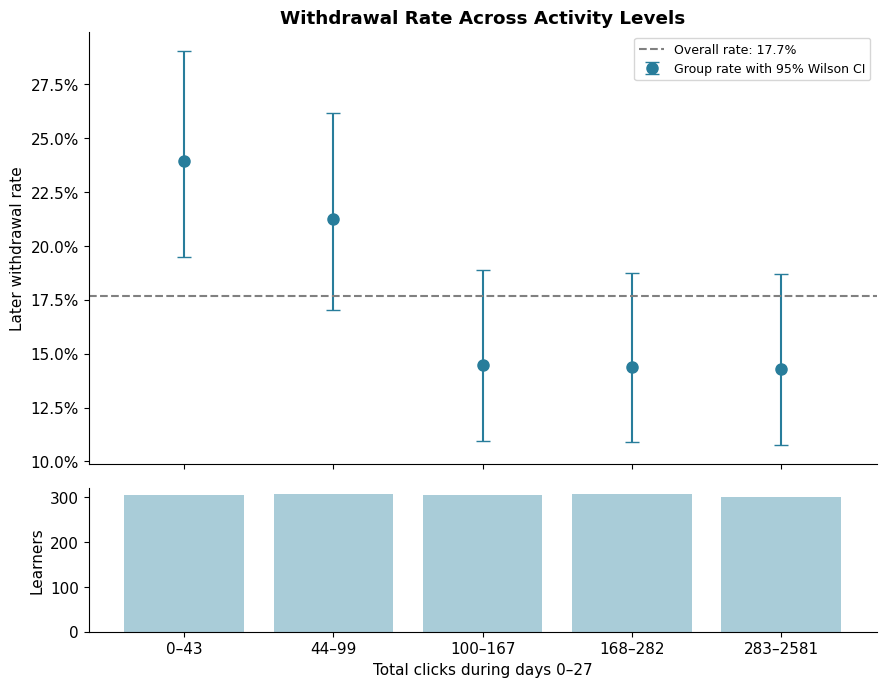

,learners,withdrawals,min_clicks,max_clicks,withdrawal_rate,ci_lower,ci_upper
0,305,73,0.0,43.0,0.239,0.195,0.290
1,306,65,44.0,99.0,0.212,0.170,0.262
2,304,44,100.0,167.0,0.145,0.110,0.189
3,306,44,168.0,282.0,0.144,0.109,0.188
4,301,43,283.0,2581.0,0.143,0.108,0.187


In [7]:
def wilson_interval(successes, totals, z=1.96):
    """Calculate Wilson confidence intervals for binomial proportions."""
    successes = np.asarray(successes, dtype=float)
    totals = np.asarray(totals, dtype=float)

    proportion = successes / totals
    denominator = 1 + z**2 / totals

    center = (
        proportion + z**2 / (2 * totals)
    ) / denominator

    margin = (
        z
        * np.sqrt(
            proportion * (1 - proportion) / totals
            + z**2 / (4 * totals**2)
        )
        / denominator
    )

    return center - margin, center + margin


train["activity_bin"] = pd.qcut(
    train["total_clicks"],
    q=5,
    duplicates="drop",
)

activity_summary = (
    train.groupby("activity_bin", observed=True)
    .agg(
        learners=("target", "size"),
        withdrawals=("target", "sum"),
        min_clicks=("total_clicks", "min"),
        max_clicks=("total_clicks", "max"),
    )
    .reset_index()
)

activity_summary["withdrawal_rate"] = (
    activity_summary["withdrawals"]
    / activity_summary["learners"]
)

lower, upper = wilson_interval(
    activity_summary["withdrawals"],
    activity_summary["learners"],
)

activity_summary["ci_lower"] = lower
activity_summary["ci_upper"] = upper

x = np.arange(len(activity_summary))
rates = activity_summary["withdrawal_rate"].to_numpy()

fig, axes = plt.subplots(
    2, 1,
    figsize=(9, 7),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
)

axes[0].errorbar(
    x,
    rates,
    yerr=np.maximum(0, np.vstack([
        rates - lower,
        upper - rates,
    ])),
    fmt="o",
    markersize=8,
    capsize=5,
    color="#287D9B",
    label="Group rate with 95% Wilson CI",
)

axes[0].axhline(
    baseline_rate,
    linestyle="--",
    color="gray",
    label=f"Overall rate: {baseline_rate:.1%}",
)

axes[0].set_title("Withdrawal Rate Across Activity Levels")
axes[0].set_ylabel("Later withdrawal rate")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(fontsize=9)

axes[1].bar(
    x,
    activity_summary["learners"],
    color="#A9CCD8",
)

axes[1].set_ylabel("Learners")
axes[1].set_xlabel("Total clicks during days 0–27")

labels = [
    f"{row.min_clicks:.0f}–{row.max_clicks:.0f}"
    for row in activity_summary.itertuples()
]

axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)

plt.tight_layout()
fig.savefig(
    output_dir / "01_activity_withdrawal_rate.png",
    dpi=200,
    bbox_inches="tight",
)
fig.savefig(output_dir / "01_activity_withdrawal_rate.svg", bbox_inches="tight")
plt.show()

display(activity_summary.drop(columns="activity_bin").round(3))

### Interpretation

The lowest-activity group (0–43 clicks) has 73 withdrawals among 305 learners: 23.9%, with a 95% Wilson interval of approximately 19.5%–29.0%. The highest group (283–2,581 clicks) has 43 among 301: 14.3%, with an interval of approximately 10.8%–18.7%.

The difference between these groups is about **9.65 percentage points**. However, rates in the three highest groups are similar (14.5%, 14.4%, and 14.3%). The pattern suggests an elevated rate in low-activity groups rather than a continuing linear improvement as clicks increase.

These are training-cohort associations. They neither establish a causal benefit from more clicks nor demonstrate predictive performance on new learners.

## 5. Participation consistency within activity groups

**Question:** Within broadly similar total activity, do rates differ by active days?

Cells show the withdrawal rate and sample size. Cells with fewer than 20 learners are masked as a display rule, not a guarantee of reliability in other cells. Quartile columns are coarse comparisons and do not fully adjust for activity volume or other factors. The color scale remains fixed at 0%–100%.

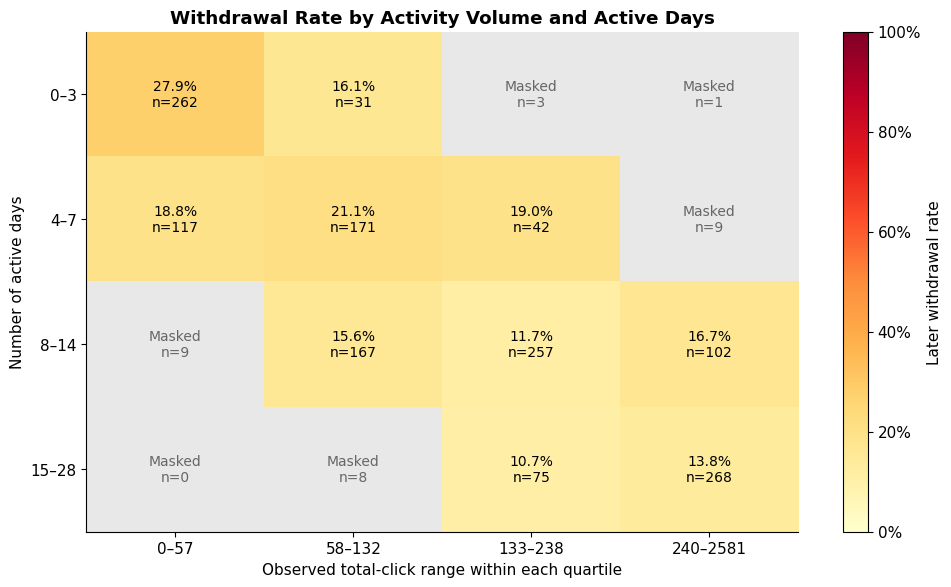

In [8]:
train["volume_group"] = pd.qcut(
    train["total_clicks"],
    q=4,
    duplicates="drop",
)

day_labels = ["0–3", "4–7", "8–14", "15–28"]

train["active_days_group"] = pd.cut(
    train["active_days"],
    bins=[-1, 3, 7, 14, 28],
    labels=day_labels,
)

rates = pd.crosstab(
    train["active_days_group"],
    train["volume_group"],
    values=train["target"],
    aggfunc="mean",
    dropna=False,
)

counts = pd.crosstab(
    train["active_days_group"],
    train["volume_group"],
    dropna=False,
)

volume_order = train["volume_group"].cat.categories

rates = rates.reindex(
    index=day_labels,
    columns=volume_order,
)

counts = counts.reindex(
    index=day_labels,
    columns=volume_order,
    fill_value=0,
)

min_group_size = 20
visible_rates = rates.where(counts >= min_group_size)

color_map = plt.get_cmap("YlOrRd").copy()
color_map.set_bad("#E8E8E8")

fig, ax = plt.subplots(figsize=(10, 6))

image = ax.imshow(
    np.ma.masked_invalid(visible_rates.to_numpy()),
    cmap=color_map,
    vmin=0,
    vmax=1,
    aspect="auto",
)

volume_ranges = (
    train.groupby("volume_group", observed=True)["total_clicks"]
    .agg(["min", "max"])
    .reindex(volume_order)
)
volume_labels = [
    f"{row['min']:.0f}–{row['max']:.0f}"
    for _, row in volume_ranges.iterrows()
]

ax.set_xticks(np.arange(len(volume_order)))
ax.set_xticklabels(volume_labels)
ax.set_yticks(np.arange(len(day_labels)))
ax.set_yticklabels(day_labels)

for row in range(len(day_labels)):
    for col in range(len(volume_order)):
        n = int(counts.iloc[row, col])
        rate = rates.iloc[row, col]

        if n >= min_group_size and pd.notna(rate):
            text = f"{rate:.1%}\nn={n}"
            color = "white" if rate > 0.55 else "black"
        else:
            text = f"Masked\nn={n}"
            color = "#666666"

        ax.text(
            col, row, text,
            ha="center",
            va="center",
            color=color,
            fontsize=10,
        )

ax.set_title("Withdrawal Rate by Activity Volume and Active Days")
ax.set_xlabel("Observed total-click range within each quartile")
ax.set_ylabel("Number of active days")

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Later withdrawal rate")
colorbar.ax.yaxis.set_major_formatter(PercentFormatter(1))

plt.tight_layout()
fig.savefig(
    output_dir / "02_volume_consistency_heatmap.png",
    dpi=200,
    bbox_inches="tight",
)
fig.savefig(output_dir / "02_volume_consistency_heatmap.svg", bbox_inches="tight")
plt.show()

### Interpretation

Within the third activity quartile, the observed withdrawal rates are 19.0% for 4–7 active days (n=42), 11.7% for 8–14 days (n=257), and 10.7% for 15–28 days (n=75). This motivates testing whether active days add predictive information beyond total clicks.

The pattern is not uniform: in the second quartile, rates are 16.1%, 21.1%, and 15.6% across the first three active-day groups. Sparse cells also limit comparisons. The heatmap does not establish a universal protective effect of consistency.

This revision labels each quartile with its actual observed minimum and maximum. Rounded interval edges in the original plot displayed an artificial `-0` and could imply overlapping boundaries.

## 6. Weekly engagement patterns

**Question:** Are outcome-group differences present throughout the window, or confined to its end?

Lines represent weekly medians; shading represents the 25th–75th percentile range across learners, **not** confidence intervals. A sequence of group medians is not an individual trajectory.

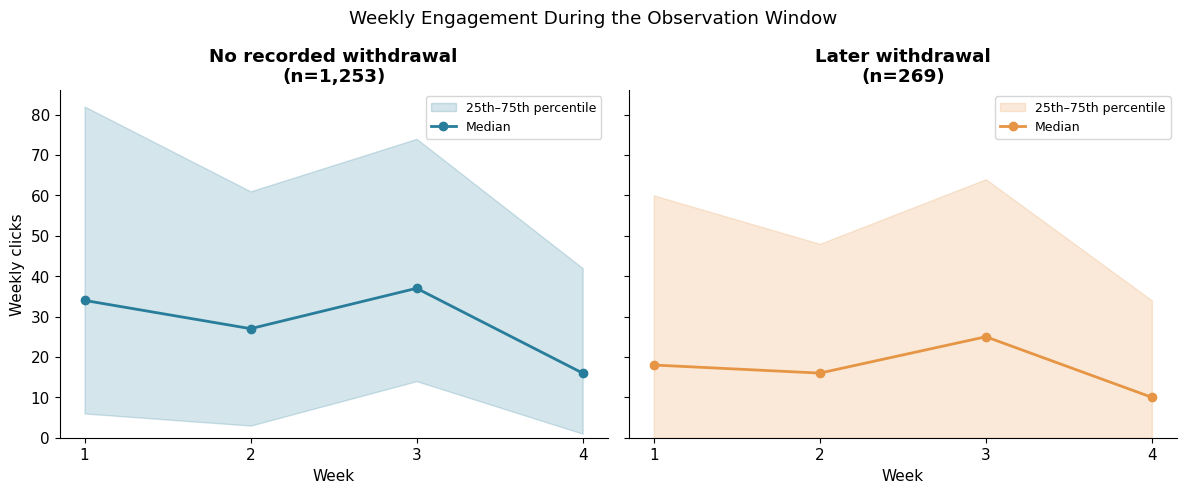

,outcome,week,median_clicks,q25_clicks,q75_clicks
0,No recorded withdrawal,1,34.0,6.0,82.0
1,No recorded withdrawal,2,27.0,3.0,61.0
2,No recorded withdrawal,3,37.0,14.0,74.0
3,No recorded withdrawal,4,16.0,1.0,42.0
4,Later withdrawal,1,18.0,0.0,60.0
5,Later withdrawal,2,16.0,0.0,48.0
6,Later withdrawal,3,25.0,0.0,64.0
7,Later withdrawal,4,10.0,0.0,34.0


In [9]:
weekly_columns = [
    "clicks_w1",
    "clicks_w2",
    "clicks_w3",
    "clicks_w4",
]

weeks = np.arange(1, 5)

groups = [
    (0, "No recorded withdrawal", "#287D9B"),
    (1, "Later withdrawal", "#E69545"),
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharex=True,
    sharey=True,
)

weekly_tables = []

for ax, (target, label, color) in zip(axes, groups):
    subset = train.loc[
        train["target"].eq(target),
        weekly_columns,
    ]

    median = subset.median().to_numpy()
    q25 = subset.quantile(0.25).to_numpy()
    q75 = subset.quantile(0.75).to_numpy()

    ax.fill_between(
        weeks,
        q25,
        q75,
        color=color,
        alpha=0.2,
        label="25th–75th percentile",
    )

    ax.plot(
        weeks,
        median,
        marker="o",
        linewidth=2,
        color=color,
        label="Median",
    )

    ax.set_title(f"{label}\n(n={len(subset):,})")
    ax.set_xlabel("Week")
    ax.set_xticks(weeks)
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=9)

    weekly_tables.append(pd.DataFrame({
        "outcome": label,
        "week": weeks,
        "median_clicks": median,
        "q25_clicks": q25,
        "q75_clicks": q75,
    }))

axes[0].set_ylabel("Weekly clicks")
fig.suptitle("Weekly Engagement During the Observation Window")

plt.tight_layout()
fig.savefig(
    output_dir / "03_weekly_engagement.png",
    dpi=200,
    bbox_inches="tight",
)
fig.savefig(output_dir / "03_weekly_engagement.svg", bbox_inches="tight")
plt.show()

weekly_summary = pd.concat(
    weekly_tables,
    ignore_index=True,
)

display(weekly_summary)

### Interpretation

Weekly medians are 34, 27, 37, and 16 clicks for non-withdrawals, compared with 18, 16, 25, and 10 for later withdrawals. The later-withdrawal group is lower in every week, but the interquartile ranges overlap substantially.

Both groups rise in week 3 and fall in week 4. A week-4 decline alone therefore cannot be treated as a withdrawal-specific signal. Course scheduling or assessment structure are possible explanations to investigate, not verified causes.

## 7. Extension: recency of activity

**Question:** How does withdrawal vary with the number of days since the last recorded activity?

The value 28 is treated separately because it means no recorded activity in the entire window. Intervals are descriptive, unadjusted 95% Wilson intervals. These groups were specified before running this extension.

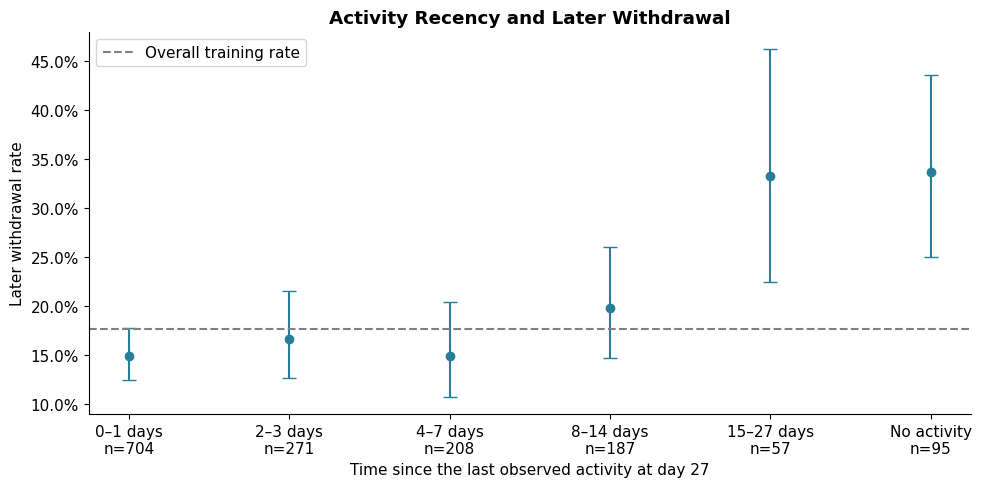

,recency_group,learners,withdrawals,withdrawal_rate
0,0–1 days,704,105,0.1491
1,2–3 days,271,45,0.1661
2,4–7 days,208,31,0.1490
3,8–14 days,187,37,0.1979
4,15–27 days,57,19,0.3333
5,No activity,95,32,0.3368


In [10]:
recency_labels = ['0–1 days', '2–3 days', '4–7 days', '8–14 days',
                  '15–27 days', 'No activity']
train['recency_group'] = pd.cut(
    train.days_since_activity,
    bins=[-1, 1, 3, 7, 14, 27, 28],
    labels=recency_labels,
)
recency_summary = (
    train.groupby('recency_group', observed=True)
    .agg(learners=('target', 'size'), withdrawals=('target', 'sum'))
    .reset_index()
)
recency_summary['withdrawal_rate'] = recency_summary.withdrawals / recency_summary.learners
low, high = wilson_interval(recency_summary.withdrawals, recency_summary.learners)
r = recency_summary.withdrawal_rate.to_numpy()
x = np.arange(len(recency_summary))
fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(x, r, yerr=np.maximum(0, np.vstack([r-low, high-r])),
            fmt='o', capsize=5, color='#287D9B')
ax.axhline(baseline_rate, color='gray', linestyle='--', label='Overall training rate')
ax.set_xticks(x)
ax.set_xticklabels([f'{label}\nn={n}' for label, n in zip(
    recency_summary.recency_group.astype(str), recency_summary.learners)])
ax.set(xlabel='Time since the last observed activity at day 27',
       ylabel='Later withdrawal rate', title='Activity Recency and Later Withdrawal')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / '04_recency_withdrawal.png', dpi=200, bbox_inches='tight')
fig.savefig(output_dir / "04_recency_withdrawal.svg", bbox_inches="tight")
plt.show()
display(recency_summary.round(4))

### Observations and interpretation

The withdrawal rate is 14.9% among learners active within the last 0–1 days (n=704), 33.3% among those last active 15–27 days earlier (n=57), and 33.7% among those with no observed activity (n=95).

Intermediate groups are not strictly ordered: the rate is 16.6% at 2–3 days and 14.9% at 4–7 days. Long inactivity is associated with higher withdrawal in this cohort, but the relationship is not a smooth increase across every group. Total activity and other differences have not been adjusted for.

### Review questions

- Which recency groups have the highest rates and how large are those groups?
- Is the pattern monotonic? How wide are the intervals?
- Does the association remain after considering total activity? This plot alone cannot answer that question.

## 8. Extension: early versus late activity

**Question:** Is activity concentrated in the first or second half of the observation window?

Early activity is week 1 + week 2; late activity is week 3 + week 4. Among learners active in both halves, a late/early ratio below 0.5 is labeled decreased, above 2 increased, and otherwise similar. These are exploratory thresholds, not validated educational categories. Zero-activity halves receive separate categories instead of arbitrary ratio substitutions.

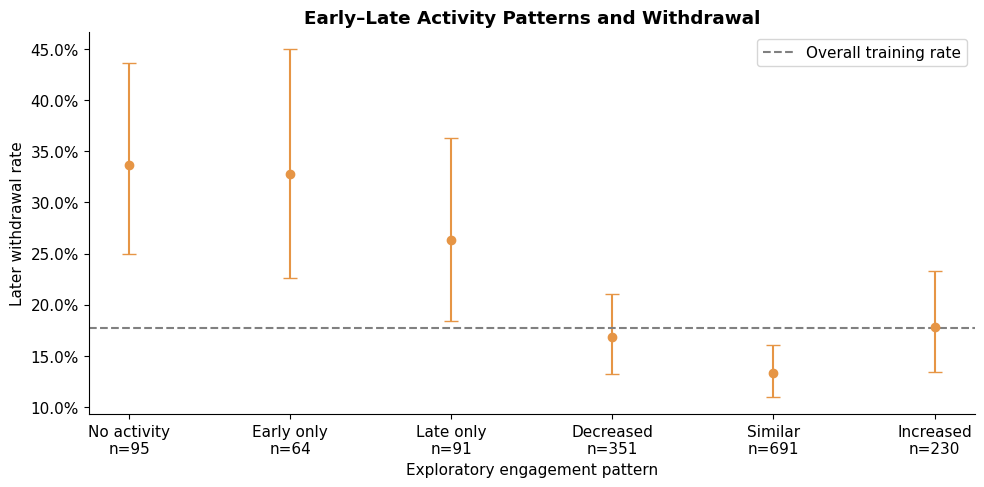

,activity_pattern,learners,withdrawals,median_total_clicks,withdrawal_rate
0,No activity,95,32,0.0,0.3368
1,Early only,64,21,28.0,0.3281
2,Late only,91,24,26.0,0.2637
3,Decreased,351,59,150.0,0.1681
4,Similar,691,92,174.0,0.1331
5,Increased,230,41,123.0,0.1783


In [11]:
train['early_clicks'] = train.clicks_w1 + train.clicks_w2
train['late_clicks'] = train.clicks_w3 + train.clicks_w4
train['activity_change'] = train.late_clicks - train.early_clicks

early, late = train.early_clicks, train.late_clicks
both_active = early.gt(0) & late.gt(0)
activity_ratio = late.div(early.where(early.gt(0)))

pattern_order = ['No activity', 'Early only', 'Late only',
                 'Decreased', 'Similar', 'Increased']
train['activity_pattern'] = pd.Categorical(
    np.select(
        [early.eq(0) & late.eq(0), early.gt(0) & late.eq(0),
         early.eq(0) & late.gt(0), both_active & activity_ratio.lt(0.5),
         both_active & activity_ratio.gt(2)],
        ['No activity', 'Early only', 'Late only', 'Decreased', 'Increased'],
        default='Similar',
    ),
    categories=pattern_order,
    ordered=True,
)
pattern_summary = (
    train.groupby('activity_pattern', observed=True)
    .agg(learners=('target', 'size'), withdrawals=('target', 'sum'),
         median_total_clicks=('total_clicks', 'median'))
    .reset_index()
)
pattern_summary['withdrawal_rate'] = pattern_summary.withdrawals / pattern_summary.learners
low, high = wilson_interval(pattern_summary.withdrawals, pattern_summary.learners)
r = pattern_summary.withdrawal_rate.to_numpy()
x = np.arange(len(pattern_summary))
fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(x, r, yerr=np.maximum(0, np.vstack([r-low, high-r])),
            fmt='o', capsize=5, color='#E69545')
ax.axhline(baseline_rate, color='gray', linestyle='--', label='Overall training rate')
ax.set_xticks(x)
ax.set_xticklabels([f'{label}\nn={n}' for label, n in zip(
    pattern_summary.activity_pattern.astype(str), pattern_summary.learners)])
ax.set(ylabel='Later withdrawal rate', xlabel='Exploratory engagement pattern',
       title='Early–Late Activity Patterns and Withdrawal')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / '05_activity_patterns.png', dpi=200, bbox_inches='tight')
fig.savefig(output_dir / "05_activity_patterns.svg", bbox_inches="tight")
plt.show()
display(pattern_summary.round(4))

### Observations and interpretation

Withdrawal rates are 33.7% for no activity (n=95), 32.8% for early-only activity (n=64), and 26.4% for late-only activity (n=91). Among learners active in both halves, rates are 16.8% for decreased activity, 13.3% for similar activity, and 17.8% for increased activity.

Increased activity is not the lowest-rate category. These groups also differ in total volume: their median total clicks are 150, 174, and 123, respectively, for decreased, similar, and increased activity. The result motivates comparing representations in a predictive model rather than treating the pattern labels as a risk ranking.

### Review questions

- Does early-only participation differ from participation in both halves?
- Are differences partly associated with total volume? Compare median total clicks in the table.
- Would conclusions change under different pattern thresholds? Do not optimize thresholds against test outcomes.

Early and late counts are sums of the existing weekly counts. They introduce no new observations; they are alternative representations that may help some models more than others.

## 9. Save aggregate results

Figures and summary CSVs are generated locally in the runtime. Colab's Save a copy in GitHub saves the notebook and included outputs; these separate files must be uploaded separately if desired. The tables below are aggregate results, not individual predictions.

In [12]:
activity_summary.to_csv(report_dir / 'activity_summary.csv', index=False)
rates.to_csv(report_dir / 'consistency_rates.csv')
counts.to_csv(report_dir / 'consistency_counts.csv')
weekly_summary.to_csv(report_dir / 'weekly_summary.csv', index=False)
recency_summary.to_csv(report_dir / 'recency_summary.csv', index=False)
pattern_summary.to_csv(report_dir / 'pattern_summary.csv', index=False)
print('Saved figures to figures/ and aggregate tables to reports/.')

Saved figures to figures/ and aggregate tables to reports/.


## 10. Distribution overlap

The ECDF includes zero-activity learners and shows the fraction of each outcome group below an activity value. The log scale reduces skew. Overlap limits simple threshold separation; these are within-cohort distributions, not estimates of individual risk.

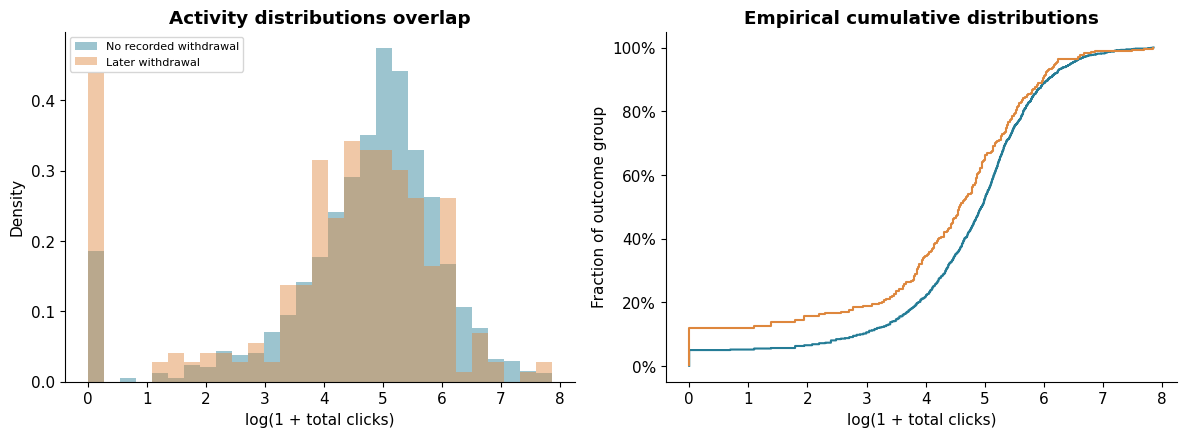

In [13]:
els.explore_distributions(train)

## 11. Recency within activity volume

This heatmap separates recent inactivity from total volume using coarse strata. Sample sizes and n<20 masking remain visible. Differences are not adjusted for every learner characteristic.

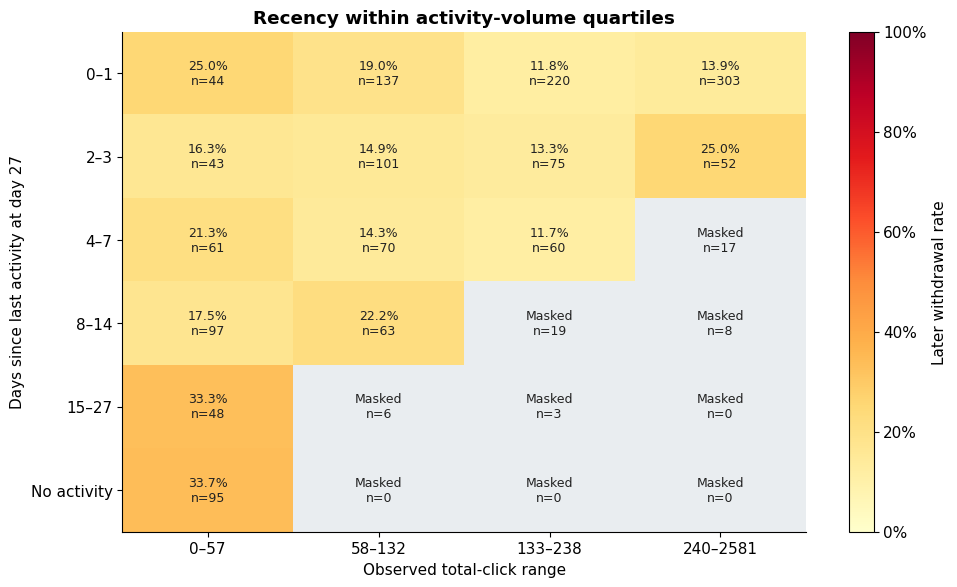

In [14]:
els.explore_recency_volume(train)

## 12. Individual early–late activity

Each point is a learner. The diagonal marks equal early and late counts, not a fitted relationship. Point overlap is substantial; no causal interpretation is implied.

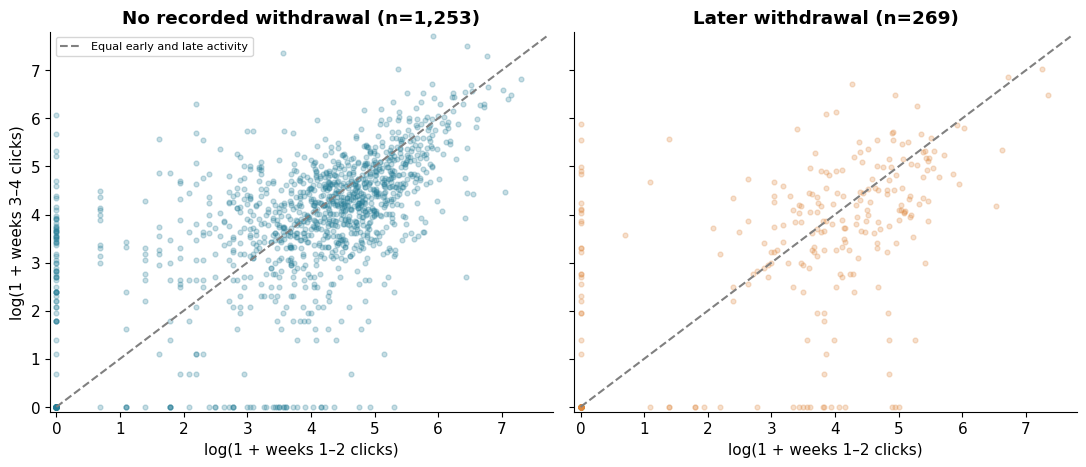

In [15]:
els.explore_early_late(train)

## 13. Feature redundancy

Spearman correlation assesses monotonic relationships among features. Weekly counts and their sums share information by construction. Correlation is not model importance; correlated features can complicate later importance analysis.

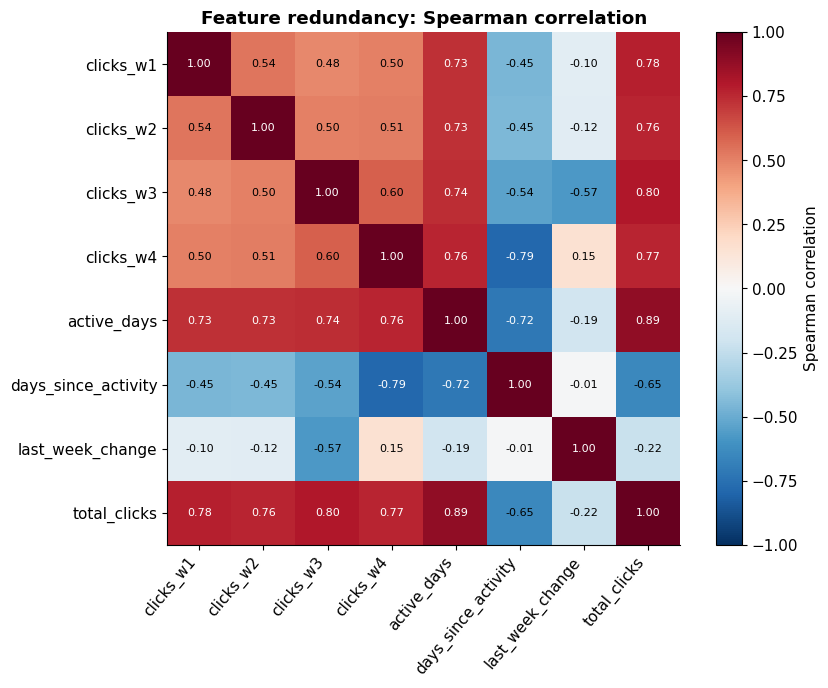

In [16]:
els.explore_correlations(train)

## 14. Zero-activity weeks

This view compares the proportion of each outcome group with no activity in each week. It complements the click medians and includes pointwise Wilson intervals. It does not track permanent dropout within the four-week window.

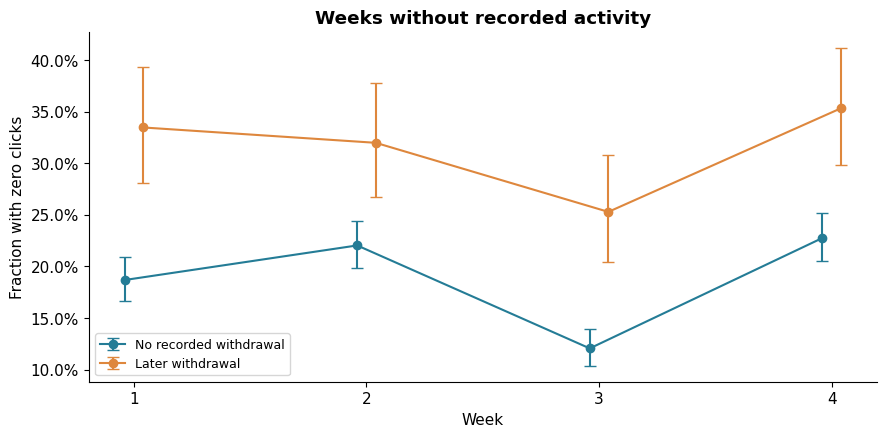

In [17]:
els.explore_zero_activity(train)

## 15. Individual weekly profiles

A fixed-seed sample of at most 100 learners per outcome is shown. Each row is normalized by its own total activity and ordered by late-activity share. This exposes within-group heterogeneity but deliberately discards absolute volume; all-zero rows remain zero. The samples do not represent outcome prevalence.

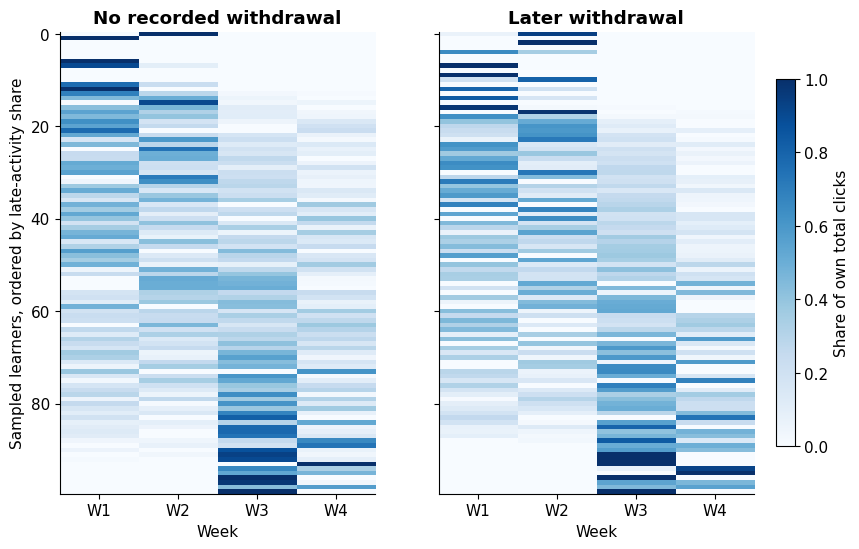

In [18]:
els.explore_individual_profiles(train)

## 16. Sensitivity of pattern definitions

The early–late pattern labels depend on chosen ratio thresholds. This sensitivity plot checks several predeclared thresholds without selecting the one that best separates outcomes. Only learners active in both halves enter this comparison.

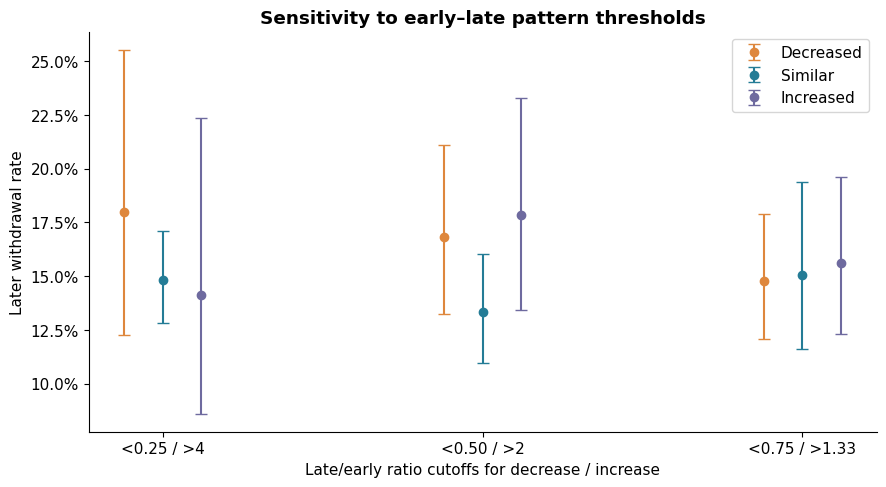

In [19]:
els.explore_pattern_sensitivity(train)

## Synthesis

Low activity and long inactivity are useful hypotheses, but their descriptive relationship with withdrawal is neither perfectly monotonic nor causal. The interquartile ranges and individual profiles show considerable heterogeneity.

Notebook 02 tests whether these signals improve ranking on a later validation cohort. Adding mathematically redundant sums does not create new information, and a more complex model need not outperform a simple rule.

## 17. Next experiment: test incremental predictive value

Notebook 02 compares these feature sets on the same chronological training/validation split:

1. Volume: total clicks only.
2. Volume + consistency + recency: total clicks, active days, days since activity.
3. Weekly representation: the eight original activity features.
4. Weekly + alternative representations: early clicks, late clicks, and activity change in addition to the original features.

The same learner must not appear in both an earlier and a later split. Scaling must be fitted on training data only. Model and configuration selection uses validation Recall@10%, with average precision as the next criterion; deterministic ties must be documented. Final evaluation remains reserved until choices are fixed.

## Limitations and authorship

- One historical UK module does not establish performance in current Korean or Canadian institutions.
- Recorded clicks omit offline learning and do not measure understanding.
- The 28-day window excludes earlier withdrawals and learners who registered after the course began.
- Descriptive subgroup intervals do not adjust for confounding or multiple comparisons.
- Coarse grouping can hide variation; masked heatmap cells indicate sparse data, not zero risk.
- No predictive model is evaluated in this notebook. Notebook 02 reports validation-only model comparisons; final-test performance and outreach effects remain unevaluated.
- Exact result-availability dates require checking before claiming a fully deployment-realistic temporal backtest.

AI assistance was used for code drafting and documentation. This revised notebook adds explanations and extensions to the original executed notebook. Its cells were re-executed on the same prepared feature CSV during revision. Personal conclusions should be reviewed by the author before publication.